In [ ]:
# Exercitiul 2
# Model Markov - arbore n=6

In [2]:
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import pyagrum as gum
import pyagrum.markov_random_field as mrfmod
import pyagrum.lib.notebook as gnb

Graphviz is not installed. 
  Please install this program in order to visualize graphical models in pyagrum. 
  See https://graphviz.org/download/


In [4]:
# Date de intrare
# n = 6 statii
# Construim arborele cu muchiile E={(S1,S2), (S1,S3), (S2,S4), (S2,S5), (S3,S6)}

In [3]:
STARI = ["Soare", "Ploaie", "Nori"]
n=6
STATII = [f"S{i}" for i in range (1, n+1)]
E=[("S1", "S2"), ("S1", "S3"), ("S2", "S4"), ("S2", "S5"), ("S3", "S6")]
p = {
    "S1": [0.50, 0.30, 0.20],
    "S2": [0.40, 0.40, 0.20],
    "S3": [0.30, 0.30, 0.40],
    "S4": [0.60, 0.20, 0.20],
    "S5": [0.20, 0.50, 0.30],
    "S6": [0.35, 0.35, 0.30],
}

Psi = np.array([[0.7, 0.2, 0.1],
                [0.2, 0.6, 0.2],
                [0.1, 0.3, 0.6]])

for s, v in p.items():
    assert all(x > 0 for x in v) and abs(sum(v) - 1) < 1e-12, s
pd.DataFrame(p, index=STARI).T

,Soare,Ploaie,Nori
S1,0.50,0.30,0.2
S2,0.40,0.40,0.2
S3,0.30,0.30,0.4
S4,0.60,0.20,0.2
S5,0.20,0.50,0.3
S6,0.35,0.35,0.3


In [6]:
# a) Graful, vecinii, verificare cicluri

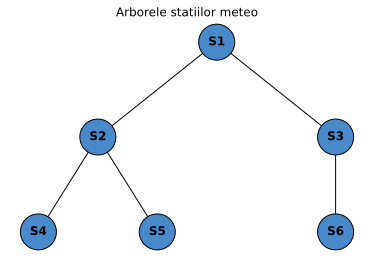

Vecinii fiecarei statii:
 N(S1) = ['S2', 'S3']
 N(S2) = ['S1', 'S4', 'S5']
 N(S3) = ['S1', 'S6']
 N(S4) = ['S2']
 N(S5) = ['S2']
 N(S6) = ['S3']


In [5]:
G = nx.Graph()
G.add_nodes_from(STATII)
G.add_edges_from(E)
pos = {"S1": (0, 2), "S2": (-1.2, 1), "S3": (1.2, 1),
       "S4": (-1.8, 0), "S5": (-0.6, 0), "S6": (1.2, 0)}
plt.figure(figsize=(5, 3.2))
nx.draw(G, pos, with_labels=True, node_size=1300, node_color="#498aca", edgecolors="#000000", font_weight="bold")
plt.title("Arborele statiilor meteo")
plt.show()
print("Vecinii fiecarei statii:")
for s in STATII:
    print(f" N({s}) = {sorted(G.neighbors(s))}")

In [17]:
# un graf neorientat cu n noduri e arbore <=> e conex si are n-1 muchii

print("Noduri:", G.number_of_nodes(), " muchii:", G.number_of_edges())
print("Conex:", nx.is_connected(G))
print("Cicluri gasite:", nx.cycle_basis(G))
print("Este arbore:", nx.is_tree(G))
assert nx.is_tree(G)

Noduri: 6  muchii: 5
Conex: True
Cicluri gasite: []
Este arbore: True


In [ ]:
# b) Modelul Markov

In [6]:
mrf = mrfmod.MarkovRandomField("Vreme")

for s in STATII:
    mrf.add(gum.LabelizedVariable(s, s, STARI))

for s in STATII:
    f = mrf.addFactor([s])
    for a in range(3):
        f[{s: a}] = p[s][a]

for (si,sj) in E:
    f = mrf.addFactor([si, sj])
    for a in range(3):
        for b in range(3):
            f[{si:a, sj:b}] = Psi[a,b]
print(mrf)

MRF{nodes: 6, edges: 5, domainSize: 729, dim: 63}


In [19]:
for(si, sj) in E:
    f = mrf.factor({si, sj})
    for a in range(3):
        for b in range(3):
            assert f[{si: a, sj:b}] == Psi[a,b]
print("Toti factorii pereche respecta orientarea (Si -> rand, Sj -> coloana)")

print(mrf.factor({"S1", "S2"}))

Toti factorii pereche respecta orientarea (Si -> rand, Sj -> coloana)

      ║  S1                         │
S2    ║Soare    │Ploaie   │Nori     │
──────║─────────│─────────│─────────│
Soare ║ 0.7000  │ 0.2000  │ 0.1000  │
Ploaie║ 0.2000  │ 0.6000  │ 0.3000  │
Nori  ║ 0.1000  │ 0.2000  │ 0.6000  │



In [ ]:
# c) Graful modelului si distributia comuna

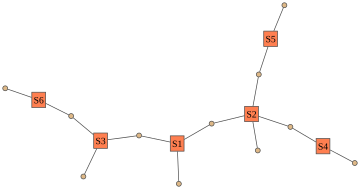

In [24]:
gnb.showMRF(mrf)

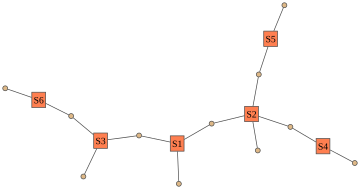

In [25]:
gnb.showMRF(mrf, view="factorgraph")

In [22]:
idx = {s: k for k, s in enumerate(STATII)}

def scor(c):
    v=1.0
    for s in STATII:
        v *= p[s][c[idx[s]]]
    for (si, sj) in E:
        v *= Psi[c[idx[si]], c[idx[sj]]]
    return v

CONFIG = list(itertools.product(range(3), repeat=n))
nenorm = np.array([scor(c) for c in CONFIG])
Z = nenorm.sum()
P = nenorm / Z
print(f"Z = {Z:.10f} (suma peste {len(CONFIG)} configuratii)")
print(f"sum P = {P.sum(): .12f}")

def nume(c):
    return ", ".join(STARI[x] for x in c)

top = np.argsort(-P)[:5]
pd.DataFrame({"configuratie (S1..S6)": [nume(CONFIG[k]) for k in top],
              "P": [P[k] for k in top]})

Z = 0.0044645588 (suma peste 729 configuratii)
sum P =  1.000000000000


,configuratie (S1..S6),P
0,"Soare, Soare, Soare, Soare, Soare, Soare",0.094866
1,"Soare, Soare, Soare, Soare, Ploaie, Soare",0.067762
2,"Soare, Soare, Soare, Soare, Soare, Ploaie",0.027105
3,"Soare, Soare, Ploaie, Soare, Soare, Ploaie",0.023233
4,"Ploaie, Ploaie, Ploaie, Soare, Ploaie, Ploaie",0.021946


In [26]:
# d) Marginale conditionate

In [51]:
def enum_conditionat(ev):
    masca = np.array([all(c[idx[s]] == STARI.index(v) for s, v in ev.items())
                      for c in CONFIG])
    q = np.where(masca, P, 0.0)
    return q / q.sum()

def marginale(ev):
    ie = mrfmod.ShaferShenoyMRFInference(mrf)
    ie.setEvidence(ev)
    ie.makeInference()
    libere = [s for s in STATII if s not in ev]
    q = enum_conditionat(ev)
    rand = []
    for s in libere:
        post = np.array(ie.posterior(s).tolist())
        ref = np.array([q[[c[idx[s]] == a for c in CONFIG]].sum() for a in range(3)])
        assert np.allclose(post, ref, atol=1e-12), (s, post, ref)
        rand.append([s, *post.round(4), STARI[int(np.argmax(post))]])
    return pd.DataFrame(rand, columns = ["statie", *STARI, "MAP marginal"]).set_index("statie")

SCENARII = {
    "A: S4 = Soare":               {"S4": "Soare"},
    "B: S3 = Ploaie":              {"S3": "Ploaie"},
    "C: S1 = Soare, S6 = Nori":    {"S1": "Soare", "S6": "Nori"},
}

for nume_sc, ev in SCENARII.items():
    print(f"\n Scenariul {nume_sc} (marginalele coincid cu enumerarea)")
    display(marginale(ev))


 Scenariul A: S4 = Soare (marginalele coincid cu enumerarea)


,Soare,Ploaie,Nori,MAP marginal
statie,,,,
S1,0.6570,0.2387,0.1042,Soare
S2,0.7173,0.2452,0.0375,Soare
S3,0.5057,0.2899,0.2044,Soare
S5,0.3986,0.4656,0.1358,Ploaie
S6,0.4412,0.3487,0.2101,Soare



 Scenariul B: S3 = Ploaie (marginalele coincid cu enumerarea)


,Soare,Ploaie,Nori,MAP marginal
statie,,,,
S1,0.3419,0.5326,0.1255,Ploaie
S2,0.4230,0.4766,0.1004,Ploaie
S4,0.5995,0.2646,0.1359,Soare
S5,0.2728,0.5571,0.1701,Ploaie
S6,0.2059,0.6176,0.1765,Ploaie



 Scenariul C: S1 = Soare, S6 = Nori (marginalele coincid cu enumerarea)


,Soare,Ploaie,Nori,MAP marginal
statie,,,,
S2,0.7733,0.1909,0.0358,Soare
S3,0.3684,0.2105,0.4211,Nori
S4,0.7674,0.1552,0.0774,Soare
S5,0.4221,0.4449,0.1330,Ploaie


In [46]:
gum.Tensor.min = lambda self: float(np.min(self.tolist()))
gum.Tensor.max = lambda self: float(np.max(self.tolist()))

def _argmax(self):
    I = gum.Instantiation(self)
    I.setFirst()
    best, sol = -1.0, []
    while not I.end():
        v = self.get(I)
        if v > best + 1e-15:
            best, sol = v, [I.todict(withLabels=False)]
        elif abs(v - best) <= 1e-15:
            sol.append(I.todict(withLabels=False))
        I.inc()
    return sol, best

gum.Tensor.argmax = _argmax

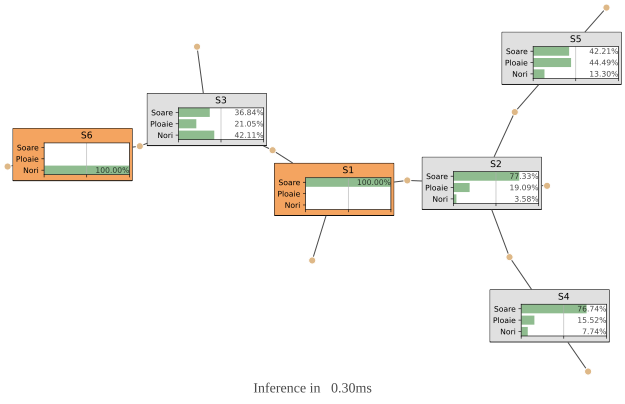

In [40]:
gnb.showInference(mrf, evs=SCENARII["C: S1 = Soare, S6 = Nori"], size="9")

In [ ]:
# e) Configuratia comuna MAP vs maximul marginalelor

In [52]:
def map_comun(ev):
    libere = [s for s in STATII if s not in ev]
    ie = mrfmod.ShaferShenoyMRFInference(mrf)
    ie.addJointTarget(set(libere))
    ie.setEvidence(ev)
    ie.makeInference()
    J = ie.jointPosterior(set(libere))
    argm, pmax = J.argmax()
    sol = {s: STARI[argm[0][s]] for s in libere}

    q = enum_conditionat(ev)
    k = int(np.argmax(q))
    sol_enum = {s: STARI[CONFIG[k][idx[s]]] for s in libere}
    assert sol == sol_enum and np.isclose(pmax, q[k]), (sol, sol_enum)
    return sol, pmax

def prob_config(ev, alegere):
    q = enum_conditionat(ev)
    full = {**ev, **alegere}
    c = tuple(STARI.index(full[s]) for s in STATII)
    return q[CONFIG.index(c)]

for nume_sc, ev in SCENARII.items():
    tab = marginale(ev)
    sol, pmax = map_comun(ev)
    tab["MAP comun"] = [sol[s] for s in tab.index]
    tab["coincid?"] = np.where(tab["MAP marginal"] == tab["MAP comun"], "da", "NU")
    alegere_marg = dict(tab["MAP marginal"])
    print(f"\n=== Scenariul {nume_sc} ===")
    display(tab)
    print(f"P(MAP comun | obs)                 = {pmax:.4f}")
    print(f"P(configurația din maxime marginale | obs) = {prob_config(ev, alegere_marg):.4f}")


=== Scenariul A: S4 = Soare ===


,Soare,Ploaie,Nori,MAP marginal,MAP comun,coincid?
statie,,,,,,
S1,0.6570,0.2387,0.1042,Soare,Soare,da
S2,0.7173,0.2452,0.0375,Soare,Soare,da
S3,0.5057,0.2899,0.2044,Soare,Soare,da
S5,0.3986,0.4656,0.1358,Ploaie,Soare,NU
S6,0.4412,0.3487,0.2101,Soare,Soare,da


P(MAP comun | obs)                 = 0.1463
P(configurația din maxime marginale | obs) = 0.1045

=== Scenariul B: S3 = Ploaie ===


,Soare,Ploaie,Nori,MAP marginal,MAP comun,coincid?
statie,,,,,,
S1,0.3419,0.5326,0.1255,Ploaie,Soare,NU
S2,0.4230,0.4766,0.1004,Ploaie,Soare,NU
S4,0.5995,0.2646,0.1359,Soare,Soare,da
S5,0.2728,0.5571,0.1701,Ploaie,Soare,NU
S6,0.2059,0.6176,0.1765,Ploaie,Ploaie,da


P(MAP comun | obs)                 = 0.0741
P(configurația din maxime marginale | obs) = 0.0700

=== Scenariul C: S1 = Soare, S6 = Nori ===


,Soare,Ploaie,Nori,MAP marginal,MAP comun,coincid?
statie,,,,,,
S2,0.7733,0.1909,0.0358,Soare,Soare,da
S3,0.3684,0.2105,0.4211,Nori,Nori,da
S4,0.7674,0.1552,0.0774,Soare,Soare,da
S5,0.4221,0.4449,0.1330,Ploaie,Soare,NU


P(MAP comun | obs)                 = 0.1477
P(configurația din maxime marginale | obs) = 0.1055


# Exercițiul 3 — Restaurarea unei imagini binare cu un MRF

Avem o imagine alb-negru de 5 × 5 pixeli, stricată de zgomot (câțiva pixeli inversați). Construim un model Markov pe grilă în care fiecare pixel e legat de vecinii lui direcți și căutăm imaginea care se potrivește cel mai bine cu ce am observat **și** e cât mai „netedă”.

Totul e verificat la final prin **enumerarea tuturor celor $2^{25} \approx 33.5$ milioane de imagini posibile**.

In [1]:
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import pyagrum as gum
import pyagrum.markov_random_field as mrfmod
import pyagrum.lib.notebook as gnb

# --- compatibilitate (aceleași reparații ca la exercițiul 2) ---
gum.config["notebook", "tensor_with_colors"] = False          # bug de afișare a tabelelor
gum.Tensor.min = lambda self: float(np.min(self.tolist()))    # bug min/max pe unele instalări
gum.Tensor.max = lambda self: float(np.max(self.tolist()))

import os, glob, shutil                                        # caută Graphviz dacă nu e în PATH
if shutil.which("dot") is None:
    for d in glob.glob(r"C:\Program Files*\Graphviz*\bin"):
        os.environ["PATH"] += os.pathsep + d
ARE_GRAPHVIZ = shutil.which("dot") is not None

print("pyAgrum", gum.__version__, "| numpy", np.__version__, "| Graphviz:", "da" if ARE_GRAPHVIZ else "nu")

pyAgrum 3.3.1 | numpy 2.5.3 | Graphviz: da


In [2]:
# Funcție de desen folosită peste tot: pixel negru = 0, alb = 1.
# Opțional: marchează cu X roșu pixelii care diferă de o imagine de referință.
def arata(img, titlu, ax, ref=None):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titlu, fontsize=10)
    ax.set_xticks(np.arange(-0.5, img.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, img.shape[0], 1), minor=True)
    ax.grid(which="minor", color="#888", linewidth=0.8)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    if ref is not None:
        for r, c in zip(*np.nonzero(img != ref)):
            ax.plot(c, r, "x", color="red", markersize=14, markeredgewidth=3)

## a) Imaginea originală

Un pătrat alb de 3 × 3 pixeli în mijlocul unui fond negru. `1` = alb, `0` = negru.

[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


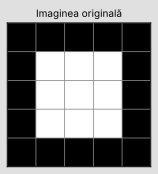

In [3]:
N = 5
original = np.zeros((N, N), dtype=int)
original[1:4, 1:4] = 1          # rândurile 1..3 și coloanele 1..3 devin albe

print(original)
fig, ax = plt.subplots(figsize=(2.6, 2.6))
arata(original, "Imaginea originală", ax)
plt.show()

## b) Imaginea cu zgomot $y$

Inversăm aleatoriu $\approx 10\%$ din pixeli ($0 \leftrightarrow 1$). Din 25 de pixeli, 10% înseamnă 2.5, așa că inversăm **exact 3 pixeli** (12%), aleși la întâmplare. Sămânța aleatoare e fixă (`SEED = 6`), deci la fiecare rulare iese aceeași imagine.

Pixeli inversați (rând, coloană): [(2, 0), (2, 2), (4, 4)]
[[0 0 0 0 0]
 [0 1 1 1 0]
 [1 1 0 1 0]
 [0 1 1 1 0]
 [0 0 0 0 1]]


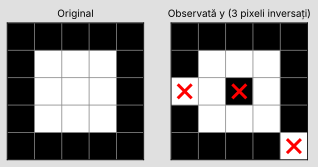

In [4]:
SEED = 6
rng = np.random.default_rng(SEED)

k = int(np.ceil(0.10 * N * N))                        # 10% din 25 = 2.5 -> 3 pixeli
pozitii = rng.choice(N * N, size=k, replace=False)    # 3 poziții diferite, din 0..24

y = original.copy().ravel()
y[pozitii] = 1 - y[pozitii]                           # inversăm: 0 -> 1, 1 -> 0
y = y.reshape(N, N)

print("Pixeli inversați (rând, coloană):", [divmod(int(p), N) for p in sorted(pozitii)])
print(y)

fig, axe = plt.subplots(1, 2, figsize=(5.4, 2.8))
arata(original, "Original", axe[0])
arata(y, f"Observată y ({k} pixeli inversați)", axe[1], ref=original)
plt.show()

Zgomotul a lovit:
* centrul pătratului, poziția (2, 2): alb → negru;
* marginea stângă, poziția (2, 0): negru → alb, lipit de pătrat;
* colțul din dreapta-jos, poziția (4, 4): negru → alb.

## c) Modelul: variabile, graf, energie

Fiecare pixel necunoscut devine o variabilă binară $x_i \in \{0, 1\}$. Graful are un nod pe pixel și o muchie între fiecare doi pixeli **vecini direcți** (sus, jos, stânga, dreapta).

noduri: 25 | muchii: 40


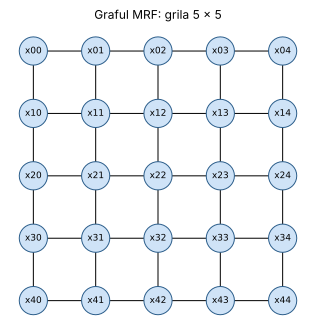

In [5]:
def nume(r, c):
    return f"x{r}{c}"                  # x00, x01, ..., x44

PIXELI = [(r, c) for r in range(N) for c in range(N)]
MUCHII = [((r, c), (r, c + 1)) for r in range(N) for c in range(N - 1)] + \
         [((r, c), (r + 1, c)) for r in range(N - 1) for c in range(N)]

G = nx.Graph()
G.add_nodes_from(nume(*p) for p in PIXELI)
G.add_edges_from((nume(*a), nume(*b)) for a, b in MUCHII)

print("noduri:", G.number_of_nodes(), "| muchii:", G.number_of_edges())
plt.figure(figsize=(4.2, 4.2))
nx.draw(G, pos={nume(r, c): (c, -r) for r, c in PIXELI}, with_labels=True,
        node_size=800, node_color="#cfe3f7", edgecolors="#2b5d8a", font_size=9)
plt.title("Graful MRF: grila 5 × 5")
plt.show()

25 de noduri și 40 de muchii (20 orizontale + 20 verticale). Un pixel din interior are 4 vecini, unul de pe margine are 3, iar un colț are doar 2.

### Energia

$$
E(x; y) \;=\; \lambda \sum_i (x_i - y_i)^2 \;+\; \sum_{(i,j)\in E} (x_i - x_j)^2, \qquad \lambda > 0.
$$

Cum valorile sunt 0 sau 1, $(a-b)^2$ e **1 dacă $a \ne b$** și **0 dacă $a = b$**. Deci energia e doar o numărătoare de „penalizări”:

* **termenul de fidelitate** $\lambda \sum_i (x_i - y_i)^2$ = $\lambda$ × numărul de pixeli în care imaginea reconstruită diferă de cea observată. Ne ține aproape de ce am văzut.
* **termenul de netezire** $\sum_{(i,j)} (x_i - x_j)^2$ = numărul de perechi de vecini cu culori diferite, adică lungimea „granițelor” alb/negru. Pedepsește pixelii izolați și contururile zimțate.
* **$\lambda$** e balanța dintre ele: $\lambda$ mare înseamnă „crede observația”, $\lambda$ mic înseamnă „prefer o imagine netedă”.

Energie mică = imagine bună. Căutăm deci imaginea cu **energia minimă**.

### Potențialele

Ca să trecem de la energie la un model Markov, folosim $P(x \mid y) \propto e^{-E(x; y)}$. Pentru că $e^{-(a+b)} = e^{-a}\, e^{-b}$, exponențiala unei sume se desface într-un produs de factori:

$$
\phi_i(x_i) = e^{-\lambda (x_i - y_i)^2}, \qquad \phi_{ij}(x_i, x_j) = e^{-(x_i - x_j)^2}.
$$

| factor | valori egale | valori diferite |
|---|---|---|
| $\phi_i(x_i)$ (pixel vs. observație) | $1$ | $e^{-\lambda}$ |
| $\phi_{ij}(x_i, x_j)$ (doi vecini) | $1$ | $e^{-1} \approx 0.368$ |

Potrivirea primește 1, nepotrivirea e „taxată” cu un număr subunitar. Cu cât energia e mai mică, cu atât produsul factorilor e mai mare, deci **minimul energiei = maximul probabilității = MAP**.

**Atenție (din indiciu):** $E$ nu e o probabilitate. E un număr de penalizări, iar probabilitatea e $P(x \mid y) = e^{-E(x;y)} / Z$.

In [6]:
def energie(x, y, lam):
    fidelitate = lam * np.sum((x - y) ** 2)
    netezire = np.sum((x[:, 1:] - x[:, :-1]) ** 2) + np.sum((x[1:, :] - x[:-1, :]) ** 2)
    return fidelitate + netezire

lam = 3
print("E(original; y) =", energie(original, y, lam))
print("E(y; y)        =", energie(y, y, lam), "  (fidelitate 0, dar multe granițe)")
print("E(tot negru; y)=", energie(np.zeros((N, N), int), y, lam), "  (netezire 0, dar fidelitate proastă)")

E(original; y) = 21
E(y; y)        = 19   (fidelitate 0, dar multe granițe)
E(tot negru; y)= 30   (netezire 0, dar fidelitate proastă)


## d) Factorii în pyAgrum și configurația MAP

### Construirea modelului

In [7]:
def construieste_mrf(y, lam):
    mrf = mrfmod.MarkovRandomField(f"imagine_lambda_{lam}")
    for r, c in PIXELI:
        mrf.add(gum.LabelizedVariable(nume(r, c), nume(r, c), ["0", "1"]))

    # factori unari: phi_i(x_i) = exp(-lambda * (x_i - y_i)^2)
    for r, c in PIXELI:
        f = mrf.addFactor([nume(r, c)])
        for v in (0, 1):
            f[{nume(r, c): v}] = np.exp(-lam * (v - y[r, c]) ** 2)

    # factori pereche: phi_ij(x_i, x_j) = exp(-(x_i - x_j)^2)
    for a, b in MUCHII:
        f = mrf.addFactor([nume(*a), nume(*b)])
        for va in (0, 1):
            for vb in (0, 1):
                f[{nume(*a): va, nume(*b): vb}] = np.exp(-(va - vb) ** 2)
    return mrf

mrf = construieste_mrf(y, lam=3)
print(mrf)

MRF{nodes: 25, edges: 40, domainSize: 10^7.5257498915995305, dim: 210}


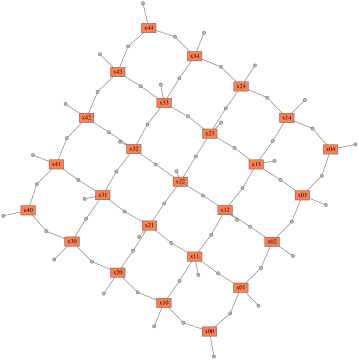

In [8]:
# graful construit de pyAgrum (desenat cu Graphviz, dacă e instalat)
if ARE_GRAPHVIZ:
    gnb.showMRF(mrf)
else:
    print("Graphviz lipsește: graful e același cu cel desenat la c).")

pyAgrum desenează modelul ca **graf de factori**: dreptunghiurile sunt pixelii, bulinele mici sunt factorii. Fiecare pixel are o bulină doar a lui (factorul unar) și câte o bulină pe fiecare legătură cu un vecin (factorul pereche). E aceeași grilă 5 × 5 de la c), doar rotită.

In [9]:
# Verificare: produsul tuturor factorilor din pyAgrum == exp(-E(x; y))
def produs_factori(mrf, x):
    config = {nume(r, c): int(x[r, c]) for r, c in PIXELI}
    p = 1.0
    for fset in mrf.factors():
        nume_var = [mrf.variable(i).name() for i in fset]
        f = mrf.factor(set(nume_var))
        p *= f[{v: config[v] for v in nume_var}]
    return p

rng_test = np.random.default_rng(0)
for x_test in [original, y, rng_test.integers(0, 2, (N, N))]:
    pf, ee = produs_factori(mrf, x_test), np.exp(-energie(x_test, y, 3))
    assert np.isclose(pf, ee)
    print(f"produs factori = {pf:.6e}   exp(-E) = {ee:.6e}")
print("Factorii din pyAgrum reproduc exact energia.")

produs factori = 7.582560e-10   exp(-E) = 7.582560e-10
produs factori = 5.602796e-09   exp(-E) = 5.602796e-09
produs factori = 1.758792e-25   exp(-E) = 1.758792e-25
Factorii din pyAgrum reproduc exact energia.


### Cum găsim MAP

pyAgrum calculează exact probabilitățile **pe fiecare pixel** (marginale), dar pentru modelele Markov nu are o funcție directă care să dea configurația MAP comună. Enunțul permite o metodă aproximativă dacă o explicăm. Folosim trei metode care se verifică una pe alta:

1. **MAP exact prin programare dinamică pe rânduri.** Privim fiecare rând ca pe o „super-variabilă” cu $2^5 = 32$ de stări. Rândurile vecine se influențează doar între ele, deci grila devine un **lanț** de 5 super-noduri. Pe un lanț, minimul se găsește exact, rând cu rând (algoritmul Viterbi / min-sum): pentru fiecare rând și fiecare stare a lui reținem cea mai mică energie posibilă până acolo.
2. **ICM (Iterated Conditional Modes)**, metoda aproximativă, cu inferența pyAgrum. Pornim de la $y$. Luăm pixelii pe rând și, ținând ceilalți pixeli ficși, punem pixelul curent la valoarea mai probabilă, $\arg\max P(x_i \mid \text{restul})$, calculată de pyAgrum. Repetăm până nu se mai schimbă nimic. Fiecare pas scade energia, dar ICM poate rămâne blocat într-un **minim local**, nu neapărat MAP-ul global.
3. **Verificare prin forță brută**: calculăm energia tuturor celor $2^{25}$ imagini și o luăm pe cea minimă.

In [10]:
# --- numărare de biți 1 (folosită la DP și la forța brută) ---
if hasattr(np, "bitwise_count"):
    popcount = np.bitwise_count
else:                                                   # numpy < 2.0
    _T = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def popcount(a):
        a = np.asarray(a, dtype=np.uint32)
        return _T[a & 255] + _T[(a >> 8) & 255] + _T[(a >> 16) & 255] + _T[(a >> 24) & 255]

def map_exact_dp(y, lam):
    # MAP exact: programare dinamică pe rânduri (fiecare rând = 32 de stări posibile)
    S = np.arange(2 ** N)                                   # starea unui rând, codată pe 5 biți
    y_rand = [sum(int(y[r, c]) << c for c in range(N)) for r in range(N)]
    cost_rand = lambda r: lam * popcount(S ^ y_rand[r]) + popcount((S ^ (S >> 1)) & (2 ** (N - 1) - 1))
    cost_trecere = popcount(S[:, None] ^ S[None, :])        # pixeli diferiți între 2 rânduri vecine

    V = cost_rand(0).astype(float)                          # cea mai mică energie până la rândul curent
    inapoi = []
    for r in range(1, N):
        M = V[:, None] + cost_trecere                       # M[s, t]: rândul anterior s, rândul curent t
        cel_mai_bun = np.argmin(M, axis=0)
        inapoi.append(cel_mai_bun)
        V = M[cel_mai_bun, S] + cost_rand(r)

    s = int(np.argmin(V)); e_min = float(V[s]); randuri = [s]
    for b in reversed(inapoi):                              # refacem drumul de la coadă la cap
        s = int(b[s]); randuri.append(s)
    randuri.reverse()
    x = np.array([[(randuri[r] >> c) & 1 for c in range(N)] for r in range(N)])
    return x, e_min


def icm_pyagrum(y, lam, max_ture=50):
    # ICM: fiecare pixel ia valoarea cea mai probabilă dată fiind restul imaginii (pyAgrum)
    mrf = construieste_mrf(y, lam)
    x = y.copy()
    for tura in range(1, max_ture + 1):
        schimbari = 0
        for r, c in PIXELI:
            ev = {nume(rr, cc): int(x[rr, cc]) for rr, cc in PIXELI if (rr, cc) != (r, c)}
            ie = mrfmod.ShaferShenoyMRFInference(mrf)
            ie.setEvidence(ev)
            ie.makeInference()
            p0, p1 = ie.posterior(nume(r, c)).tolist()          # P(x_i = 0 | rest), P(x_i = 1 | rest)
            nou = x[r, c] if np.isclose(p0, p1) else int(p1 > p0)   # la egalitate nu schimbăm
            if nou != x[r, c]:
                x[r, c] = nou
                schimbari += 1
        if schimbari == 0:
            return x, tura
    return x, max_ture


def forta_bruta(y, lambdas):
    # încearcă toate cele 2^25 imagini (în bucăți de 2^21) și reține minimul energiei pentru fiecare lambda
    y_bits = np.uint32(sum(int(y[r, c]) << (r * N + c) for r, c in PIXELI))
    masca_oriz = np.uint32(sum(1 << (r * N + c) for r in range(N) for c in range(N - 1)))
    masca_vert = np.uint32(sum(1 << (r * N + c) for r in range(N - 1) for c in range(N)))
    rez = {lam: [np.inf, None, 0] for lam in lambdas}      # [energie minimă, imagine, câte imagini o ating]
    for start in range(0, 2 ** (N * N), 2 ** 21):
        v = np.arange(start, start + 2 ** 21, dtype=np.uint32)
        D = popcount(v ^ y_bits).astype(float)                                     # pixeli diferiți de y
        S = (popcount((v ^ (v >> 1)) & masca_oriz) + popcount((v ^ (v >> N)) & masca_vert)).astype(float)
        for lam in lambdas:
            E = lam * D + S
            m = E.min(); cate = int(np.sum(np.isclose(E, m)))
            if m < rez[lam][0] - 1e-9:
                rez[lam] = [m, int(v[np.argmin(E)]), cate]
            elif np.isclose(m, rez[lam][0]):
                rez[lam][2] += cate
    for lam in lambdas:
        b = rez[lam][1]
        rez[lam][1] = np.array([[(b >> (r * N + c)) & 1 for c in range(N)] for r in range(N)])
    return rez

lambda = 3
MAP exact (DP):     E = 18.00
Forță brută:        E = 18.00   (imagini cu energia minimă: 1)
ICM (pyAgrum):      E = 18.00   (oprit după 2 ture)
DP și forța brută găsesc aceeași imagine MAP.
[[0 0 0 0 0]
 [0 1 1 1 0]
 [1 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 1]]


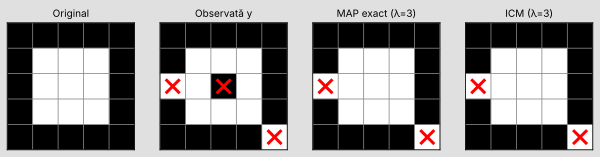

X roșu = pixel diferit de original


In [11]:
lam = 3
x_map, e_map = map_exact_dp(y, lam)
x_icm, ture = icm_pyagrum(y, lam)
bf = forta_bruta(y, [lam])[lam]

print(f"lambda = {lam}")
print(f"MAP exact (DP):     E = {e_map:.2f}")
print(f"Forță brută:        E = {bf[0]:.2f}   (imagini cu energia minimă: {bf[2]})")
print(f"ICM (pyAgrum):      E = {energie(x_icm, y, lam):.2f}   (oprit după {ture} ture)")
assert np.array_equal(x_map, bf[1]) and np.isclose(e_map, bf[0])
print("DP și forța brută găsesc aceeași imagine MAP.")
print(x_map)

fig, axe = plt.subplots(1, 4, figsize=(10.5, 2.9))
arata(original, "Original", axe[0])
arata(y, "Observată y", axe[1], ref=original)
arata(x_map, f"MAP exact (λ={lam})", axe[2], ref=original)
arata(x_icm, f"ICM (λ={lam})", axe[3], ref=original)
plt.show()
print("X roșu = pixel diferit de original")

Cu $\lambda = 3$, MAP-ul repară centrul pătratului: un pixel cu 4 vecini albi costă $\lambda = 3$ dacă îl facem alb și $4$ dacă îl lăsăm negru, deci alb câștigă. Pixelii de zgomot de pe margine și din colț rămân însă: au doar 2–3 vecini, deci „presiunea” vecinilor e mai mică decât $\lambda$.

**Bonus: probabilitatea fiecărui pixel, calculată exact de pyAgrum.** Fără nicio evidență suplimentară ($y$ e deja în factori), `ShaferShenoyMRFInference` dă pentru fiecare pixel $P(x_i = 1 \mid y)$.

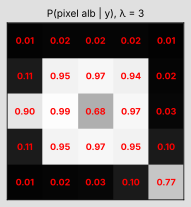

In [12]:
ie = mrfmod.ShaferShenoyMRFInference(construieste_mrf(y, 3))
ie.makeInference()
P1 = np.array([[ie.posterior(nume(r, c)).tolist()[1] for c in range(N)] for r in range(N)])

fig, ax = plt.subplots(figsize=(3.4, 3.2))
im = ax.imshow(P1, cmap="gray", vmin=0, vmax=1)
for r, c in PIXELI:
    ax.text(c, r, f"{P1[r, c]:.2f}", ha="center", va="center",
            color="red", fontsize=9, fontweight="bold")
ax.set_title("P(pixel alb | y), λ = 3", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
plt.show()

Pixelii siguri au probabilități aproape de 0 sau 1. Cei atinși de zgomot sunt mai nesiguri: centrul (0.68) și colțul din dreapta-jos (0.77). Modelul „ezită” exact acolo unde observația și vecinii nu se potrivesc. Ca la exercițiul 2, alegerea pixel cu pixel după aceste probabilități (MAP marginal) nu e garantat aceeași cu MAP-ul comun; aici, pentru $\lambda = 3$, cele două coincid.

## e) Mai multe valori ale lui $\lambda$

Pe lângă valorile sugerate (0.3, 1, 3) am adăugat 1.8 (între 1 și 3) și 5 (foarte mare). Pentru fiecare calculăm MAP-ul exact și rezultatul ICM, apoi numărăm pixelii greșiți față de imaginea **originală**.

In [13]:
LAMBDAS = [0.3, 1, 1.8, 3, 5]
bf_toate = forta_bruta(y, LAMBDAS)                     # o singură trecere prin cele 2^25 imagini

rezultate, imagini = [], {}
for lam in LAMBDAS:
    x_map, e_map = map_exact_dp(y, lam)
    x_icm, ture = icm_pyagrum(y, lam)
    assert np.array_equal(x_map, bf_toate[lam][1]) and bf_toate[lam][2] == 1   # MAP unic și verificat
    imagini[lam] = (x_map, x_icm)
    rezultate.append({
        "lambda": lam,
        "E(MAP)": round(e_map, 2),
        "E(ICM)": round(float(energie(x_icm, y, lam)), 2),
        "greșiți MAP": int((x_map != original).sum()),
        "greșiți ICM": int((x_icm != original).sum()),
        "MAP schimbă din y": int((x_map != y).sum()),
    })

print(f"Imaginea observată y are {(y != original).sum()} pixeli greșiți.")
print("Toate imaginile MAP sunt unice și confirmate prin forță brută.")
pd.DataFrame(rezultate).set_index("lambda")

Imaginea observată y are 3 pixeli greșiți.
Toate imaginile MAP sunt unice și confirmate prin forță brută.


,E(MAP),E(ICM),greșiți MAP,greșiți ICM,MAP schimbă din y
lambda,,,,,
0.3,3.0,8.0,9,11,10
1.0,10.0,15.0,9,1,10
1.8,16.6,16.6,1,1,2
3.0,18.0,18.0,2,2,1
5.0,19.0,19.0,3,3,0


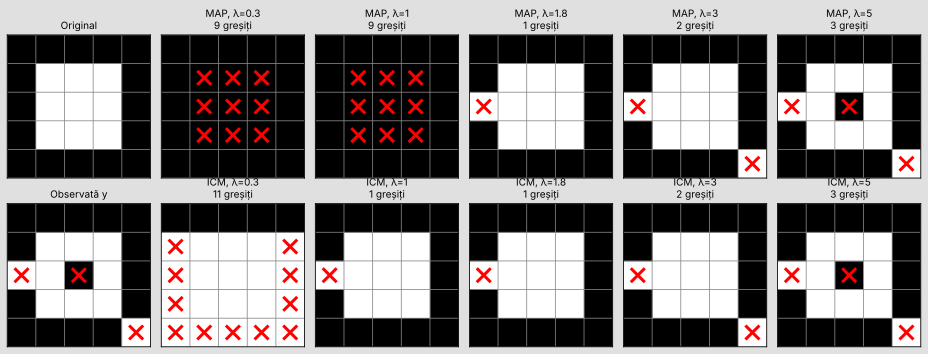

In [14]:
fig, axe = plt.subplots(2, len(LAMBDAS) + 1, figsize=(13, 5))
arata(original, "Original", axe[0, 0])
arata(y, "Observată y", axe[1, 0], ref=original)
for k, lam in enumerate(LAMBDAS, start=1):
    x_map, x_icm = imagini[lam]
    arata(x_map, f"MAP, λ={lam}\n{(x_map != original).sum()} greșiți", axe[0, k], ref=original)
    arata(x_icm, f"ICM, λ={lam}\n{(x_icm != original).sum()} greșiți", axe[1, k], ref=original)
plt.tight_layout()
plt.show()

### Interpretare

**De ce un $\lambda$ mic favorizează netezirea.** Când $\lambda$ e mic, a contrazice observația costă puțin, iar fiecare graniță alb/negru costă 1. Pătratul alb are un contur de 12 muchii, deci păstrarea lui costă cel puțin 12. Să-l ștergem complet costă doar $\lambda$ × (numărul de pixeli albi din $y$, adică 10). Pentru $\lambda = 0.3$ și $\lambda = 1$, ștergerea e mai ieftină ($3$, respectiv $10 < 12$), așa că **MAP-ul e o imagine complet neagră**: perfect netedă, dar pătratul a dispărut (9 pixeli greșiți). Asta e **netezire excesivă**.

**Echilibru ($\lambda = 1.8$).** Pătratul devine prea scump de șters ($1.8 \times 10 = 18$, mai mult decât conturul lui), dar zgomotul izolat tot e corectat. Centrul se repară (4 vecini albi > 1.8), la fel și colțul (2 vecini negri > 1.8). Rămâne o singură greșeală: pixelul (2, 0), lipit de pătrat, care are doar 2 vecini negri și unul alb. Acesta e cel mai bun rezultat.

**De ce un $\lambda$ mare favorizează fidelitatea.** La $\lambda = 3$, colțul nu se mai repară (2 vecini < 3). La $\lambda = 5$ niciun pixel nu se mai schimbă, pentru că un pixel are cel mult 4 vecini, deci netezirea nu poate „plăti” niciodată costul $\lambda = 5$ al unei schimbări. **MAP-ul devine chiar imaginea observată $y$**, cu tot zgomotul.

Pe scurt: $\lambda$ mic = „cred în netezime”, $\lambda$ mare = „cred în observație”. Valoarea bună e la mijloc.

**ICM vs. MAP exact.**
* Pentru $\lambda \ge 1.8$, ICM găsește exact MAP-ul.
* Pentru $\lambda = 0.3$ și $\lambda = 1$, ICM se oprește într-un **minim local**, cu energie mai mare decât MAP-ul. Ștergerea pătratului ar cere schimbarea multor pixeli deodată, iar ICM schimbă câte unul și fiecare pas trebuie să scadă energia.
* La $\lambda = 1$, minimul local al ICM arată chiar mai bine decât MAP-ul (1 pixel greșit în loc de 9). Asta nu înseamnă că ICM e mai bun: MAP e cea mai bună imagine *după modelul ales*, iar cu $\lambda = 1$ modelul însuși preferă o imagine neagră. Problema e alegerea lui $\lambda$, nu metoda.
* La $\lambda = 0.3$, ICM pornește să albească pixeli din aproape în aproape și ajunge la o imagine cu 11 pixeli greșiți.

**Concluzie:** MAP-ul exact minimizează energia, deci depinde de $\lambda$. ICM e rapid, dar poate găsi doar un minim local; aici confirmăm prin forță brută când a găsit MAP-ul global și când nu.